In [2]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
from scipy.signal import find_peaks, welch
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

# 'Bak' and 'Pelang' often have sharp, metallic FM-like transients
TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

In [3]:
y_decay = y[int(0.05 * sr):] 
freqs, psd = welch(y_decay, fs=sr, nperseg=8192)
psd_db = 10 * np.log10(psd / np.max(psd))

peaks, _ = find_peaks(psd_db, prominence=10)
sorted_peaks_by_freq = np.sort(peaks)

if len(sorted_peaks_by_freq) < 2:
    print("Not enough prominent peaks to calculate C:M ratio.")
else:
    # 1. The Carrier
    f0_idx = sorted_peaks_by_freq[0]
    carrier_freq = freqs[f0_idx]
    
    # 2. The Modulator (Find the loudest peak that is NOT the fundamental)
    # Mask out the fundamental
    psd_db_masked = psd_db.copy()
    psd_db_masked[max(0, f0_idx-5) : min(len(psd_db_masked), f0_idx+5)] = -100
    
    modulator_idx = np.argmax(psd_db_masked[peaks])
    modulator_freq = freqs[peaks[modulator_idx]]
    
    # 3. Calculate Ratio
    cm_ratio = modulator_freq / carrier_freq
    
    print("--- FM Synthesis Oscillator Setup ---")
    print(f"Carrier Frequency (C): {carrier_freq:.1f} Hz")
    print(f"Modulator Frequency (M): {modulator_freq:.1f} Hz")
    print(f"Optimal C:M Ratio: 1.00 : {cm_ratio:.3f}")

--- FM Synthesis Oscillator Setup ---
Carrier Frequency (C): 26.9 Hz
Modulator Frequency (M): 296.1 Hz
Optimal C:M Ratio: 1.00 : 11.000


In [4]:
# Calculate Spectral Centroid over time
cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=1024, hop_length=256)[0]
frames = range(len(cent))
t_ms = librosa.frames_to_time(frames, sr=sr, hop_length=256) * 1000 

# Smooth the centroid to remove jitter (creates a clean FM envelope)
cent_smooth = np.convolve(cent, np.ones(5)/5, mode='same')

# Normalize Centroid to a 0.0 - 1.0 Modulation Index scale
# (0.0 = pure sine wave carrier, 1.0 = maximum metallic modulator bandwidth)
index_env = (cent_smooth - np.min(cent_smooth)) / (np.max(cent_smooth) - np.min(cent_smooth) + 1e-6)

print("\n--- FM Synthesis Envelope Setup ---")
print(f"Peak Modulation Index achieved at: {t_ms[np.argmax(index_env)]:.1f} ms")
print(f"Time to decay to 10% Index (Pure Sine Tail): {t_ms[np.where(index_env < 0.1)[0][0]] if np.any(index_env < 0.1) else 'N/A'} ms")


--- FM Synthesis Envelope Setup ---
Peak Modulation Index achieved at: 17.4 ms
Time to decay to 10% Index (Pure Sine Tail): 69.65986394557822 ms


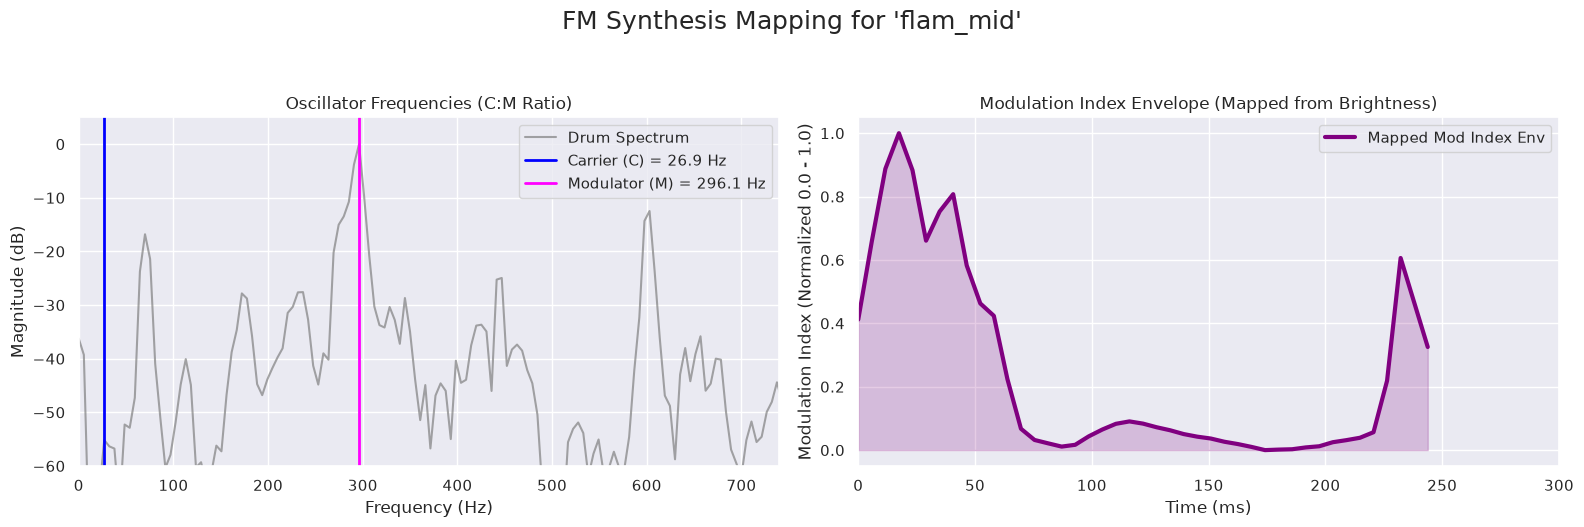

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f"FM Synthesis Mapping for '{TARGET_STROKE}'", fontsize=18, y=1.05)

# Plot 1: Carrier vs Modulator Spectrum
axes[0].plot(freqs, psd_db, color='gray', alpha=0.7, label='Drum Spectrum')
axes[0].axvline(carrier_freq, color='blue', linewidth=2, label=f'Carrier (C) = {carrier_freq:.1f} Hz')
axes[0].axvline(modulator_freq, color='magenta', linewidth=2, label=f'Modulator (M) = {modulator_freq:.1f} Hz')
axes[0].set_title("Oscillator Frequencies (C:M Ratio)")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude (dB)")
axes[0].set_xlim(0, max(carrier_freq, modulator_freq) * 2.5)
axes[0].set_ylim(-60, 5)
axes[0].legend()

# Plot 2: Modulation Index Envelope
axes[1].plot(t_ms, index_env, color='purple', linewidth=3, label='Mapped Mod Index Env')
axes[1].fill_between(t_ms, index_env, color='purple', alpha=0.2)
axes[1].set_title("Modulation Index Envelope (Mapped from Brightness)")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Modulation Index (Normalized 0.0 - 1.0)")
axes[1].set_xlim(0, 300) # Show first 300ms
axes[1].legend()

plt.tight_layout()
plt.show()